# Study NNN: <title>  (replication notebook)

**Question.** <one sentence: what does this study test, and which kit goal does it serve (CLAUDE.md G1 fast, G2 efficient,
G3 reliable, G4 accurate, G5 autonomous)?>

| Field | Entry |
|---|---|
| Study | `research/NNN_<slug>/` |
| PREREG commit | `<sha>` (pre-registered before any result existed) |
| Verdict | <adopt / park / kill, or "pending" until RESULT.md is written> |
| Entry point | **this notebook** (`replicate.ipynb`); there are no study-specific `.py` scripts |

This notebook is the single entry point for the study (Sharif directive 2026-10-27). Press **Run All**
and it loads the data, computes every result, writes the saved outputs (`output/`), builds every figure
(`final_report/figures/`) and the numbers file (`final_report/key_numbers.json`), prints the headline
table and finally verifies the saved outputs against their checksums (PASS / FAIL).

> **Template note.** In `research/_templates/` the notebook runs a toy demonstration on synthetic agent-trial data
> and writes to a temporary folder. Copy it to `research/NNN_<slug>/replicate.ipynb`, set `STUDY_SLUG`
> in the setup cell, delete the "TEMPLATE" markers and replace each step body with the study's steps.

## How to run

1. **Kernel:** one-time setup from the repo root: `pip install -r requirements.txt` (it installs `ipykernel`,
   which provides the kernel). Then select **Python 3** (kernel name `python3`) in VS Code / Cursor / JupyterLab.
2. **Run All** (top to bottom). No prompts, no hidden state: every cell depends only on earlier cells.
   Headless: `python scripts/research/run_notebook.py research/NNN_<slug>/replicate.ipynb` runs it with nobody
   pressing anything and prints `PASS` or `FAIL`.
3. **RERUN flag** (first code cell). `RERUN = False` (default) reuses cached outputs, so Run All on a
   finished study is fast and rebuilds the figures from the saved outputs. `RERUN = True` recomputes
   every heavy step and overwrites `output/`.
4. **Runtime:** <fill in: cached run about N seconds; full RERUN about M minutes, peak memory G GB>.
5. **Data needed:** <fill in: this study's rows in `research/TRIAL_LOG.tsv`, plus any saved run artifacts>.
   The template needs no data. API keys come from `.env` and are never committed (this repo is public,
   CLAUDE.md section 9).
6. **Memory:** the setup cell caps BLAS threads at 6 (`OMP_NUM_THREADS` and friends); check free memory
   before a heavy `RERUN = True`.
7. The last cell prints **PASS** or **FAIL** for the checksum verification and raises on FAIL.

**Rules this notebook follows** (the `research-report` skill, "Replication notebook standard"):
reusable logic is imported from the repo (for example `scripts/`), not copied in; the notebook holds only the
study-specific steps;
numbers in the report come from the saved outputs only; the committed file is saved **executed**, with
outputs visible and no error outputs.

## Step 0. Setup

**What:** finds the repository root (walks up to the folder holding `CLAUDE.md` and `ROADMAP.md`), fixes
the seeds, caps BLAS threads, and defines the output folders and the `RERUN` flag.
**Why:** portable paths (no hardcoded drive letters) and a reproducible, memory-safe start.
**Inputs:** none. **Outputs:** the constants `ROOT`, `STUDY`, `OUT`, `FIG`, `SEED`, `RERUN`.

In [1]:
# Sharif Amlani
# Python 3.13
# Fall 2026

######################## Code Summary ##################
# ********************* v1 **********************
# Study NNN replication notebook: the single entry point (Run All). <one-line summary of the study>
# Inputs: <research/TRIAL_LOG.tsv rows, run artifacts>   Outputs: output/*, final_report/figures/*, final_report/key_numbers.json

######################### Prelude #####################
RERUN = False                  # True = recompute every heavy step and overwrite output/; False = reuse cached outputs
STUDY_SLUG = "_templates"      # research/<STUDY_SLUG>/ ; CHANGE to "NNN_<slug>" when you copy this notebook
SEED = 1993                    # one seed for everything

######################### Library #####################
import hashlib
import json
import os
import random
import re
import sys
import tempfile
import time
from pathlib import Path

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):   # thread caps (at most 6 per heavy job),
    os.environ.setdefault(_v, "6")                                          # set before numpy loads

import matplotlib
import numpy as np
import pandas as pd

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import display  # noqa: E402

T_START = time.time()


def find_root(start: Path | None = None) -> Path:
    """Walk up from the working directory to the folder that holds CLAUDE.md and ROADMAP.md (portable-python-paths)."""
    p = (start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "CLAUDE.md").exists() and (q / "ROADMAP.md").exists():
            return q
    raise RuntimeError("CLAUDE.md + ROADMAP.md not found above " + str(p) + ": open the notebook inside the autonomous repo")


ROOT = find_root()
os.environ.setdefault("SOURCE_DATE_EPOCH", "1761523200")   # makes saved PDFs byte-stable across runs
random.seed(SEED)
np.random.seed(SEED)

######################### Paths #######################
STUDY = ROOT / "research" / STUDY_SLUG
IS_TEMPLATE = STUDY_SLUG.startswith("_")
if IS_TEMPLATE:                                  # the template writes to a scratch folder so the repo stays clean
    _scratch = Path(tempfile.mkdtemp(prefix="replicate_demo_"))
    OUT, FR = _scratch / "output", _scratch / "final_report"
else:
    OUT, FR = STUDY / "output", STUDY / "final_report"
FIG = FR / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

print(f"repo root : {ROOT.name}   study: {STUDY_SLUG}   RERUN={RERUN}   SEED={SEED}")
print(f"threads   : OMP_NUM_THREADS={os.environ['OMP_NUM_THREADS']}")


repo root : autonomous   study: _templates   RERUN=False   SEED=1993
threads   : OMP_NUM_THREADS=6


## Step 0b. Helpers (cache, checksums, figures)

**What:** small functions used by every later step: `sha256` (file checksum), `cached_json` /
`cached_parquet` (compute once, reuse unless `RERUN`), `bootstrap_ci` (seeded percentile bootstrap CI of a
mean), and `save_figure` (applies the research-report
visualization standard and records the figure in `figures/manifest.json`).
**Why:** one place for the caching and figure rules, so every step is idempotent and `check_report.py`
finds a title, axis labels and plain-English legend for every figure.
**Inputs:** `RERUN`, `OUT`, `FIG`. **Outputs:** the functions only.

In [2]:
######################### Functions ###################
def sha256(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def bootstrap_ci(x, n_boot: int = 2000, level: float = 0.95, seed: int = SEED) -> tuple:
    """Percentile bootstrap CI for the mean of `x` (resamples trials with replacement; seeded, so reruns match)."""
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    lo, hi = np.quantile(means, [(1 - level) / 2, (1 + level) / 2])
    return float(lo), float(hi)


def cached_json(path: Path, build):
    """Return json at `path` if present and not RERUN, else call build() and save it."""
    if path.exists() and not RERUN:
        print(f"cached   {path.name}")
        return json.loads(path.read_text(encoding="utf-8"))
    obj = build()
    path.write_text(json.dumps(obj, indent=1, default=float), encoding="utf-8")
    print(f"computed {path.name}")
    return obj


def cached_parquet(path: Path, build):
    """Return the parquet table at `path` if present and not RERUN, else call build() and save it."""
    if path.exists() and not RERUN:
        print(f"cached   {path.name}")
        return pd.read_parquet(path)
    df = build()
    df.to_parquet(path)
    print(f"computed {path.name}")
    return df


def is_code_like(label: str) -> bool:
    """Same rule as make_figures.py / check_report.py: snake_case, pipes or bare lowercase tokens are codes."""
    s = str(label).strip()
    return (not s) or "_" in s or "|" in s or bool(re.fullmatch(r"[a-z0-9]+", s))


def save_figure(fig, name: str, title: str, xlabel: str, ylabel: str, legend: list) -> None:
    """Save `fig` as FIG/name (PDF), show it inline, and record title / axis labels / legend in figures/manifest.json."""
    bad = [x for x in legend if is_code_like(x)]
    if bad or not (title.strip() and xlabel.strip() and ylabel.strip()):
        raise ValueError(f"figure {name}: needs a title, axis labels and plain-English legend labels (code-like: {bad})")
    fig.savefig(FIG / name, bbox_inches="tight")
    mp = FIG / "manifest.json"
    man = json.loads(mp.read_text(encoding="utf-8")) if mp.exists() else {}
    man[name] = {"title": title, "xlabel": xlabel, "ylabel": ylabel, "legend": legend}
    mp.write_text(json.dumps(man, indent=2), encoding="utf-8")
    display(fig)
    plt.close(fig)


## Step 1. Load the data  *(TEMPLATE: replace with the study's data load)*

**What:** reads the study's trials from `research/TRIAL_LOG.tsv` (one row per agent run: arm, task, metric,
value, cost). The template simulates a toy trial table, 2 arms x 3 runs x 5 tasks with the columns `arm`,
`run`, `task`, `success`, `cost_usd`, so that the notebook runs end to end with no API spend.
**Why:** a study's numbers come from the logged trials, never from numbers retyped by hand (CLAUDE.md
section 5: every run is appended to the trial log).
**Inputs:** `research/TRIAL_LOG.tsv` filtered to this study in a real study. **Outputs:** the in-memory
table `trials` used by Step 2.

In [3]:
######################### Upload Data #################
# Real study (replace the toy block):
#   log = pd.read_csv(ROOT / "research" / "TRIAL_LOG.tsv", sep="\t")
#   trials = log[log["study"] == STUDY_SLUG]   # then pivot metric/value into `success`; keep `cost_usd`
rng = np.random.default_rng(SEED)
ARMS = {"Baseline (no plugin)": 0.55, "Kit": 0.70}   # toy true success rates; baseline first; plain-English names
trials = pd.DataFrame([
    {"arm": arm, "run": run, "task": f"task_{t:02d}", "success": int(rng.random() < p),
     "cost_usd": round(float(rng.lognormal(np.log(0.40), 0.30)), 4)}
    for arm, p in ARMS.items() for run in range(1, 4) for t in range(1, 6)
])
print(f"{len(trials)} trials: {trials['arm'].nunique()} arms x {trials['run'].nunique()} runs x {trials['task'].nunique()} tasks")


30 trials: 2 arms x 3 runs x 5 tasks


## Step 2. Compute the results  *(TEMPLATE: replace with the study's steps)*

**What:** the heavy computation. Here: each arm's task success rate with a 95% bootstrap confidence
interval (`bootstrap_ci`, Step 0b) and its mean usage per task (tokens/task, CLAUDE.md G2).
**Why:** these are the numbers the PREREG thresholds are applied to.
**Inputs:** `trials`. **Outputs:** `output/results.json` (cached; recomputed only if
`RERUN = True` or the file is missing). Every other heavy step follows the same pattern: one
`cached_json` / `cached_parquet` call per saved output.

In [4]:
######################### Analysis #####################
def compute_results() -> dict:
    out = {"n_trials": int(len(trials)), "arms": {}}
    for arm, g in trials.groupby("arm", sort=False):   # sort=False keeps the baseline first
        lo, hi = bootstrap_ci(g["success"])
        out["arms"][arm] = {"n_trials": int(len(g)), "success_rate": float(g["success"].mean()),
                            "ci_low": lo, "ci_high": hi, "cost_per_task": float(g["cost_usd"].mean())}
    return out


results = cached_json(OUT / "results.json", compute_results)
print(results)


computed results.json
{'n_trials': 30, 'arms': {'Baseline (no plugin)': {'n_trials': 15, 'success_rate': 0.4666666666666667, 'ci_low': 0.2, 'ci_high': 0.7333333333333333, 'cost_per_task': 0.42961333333333335}, 'Kit': {'n_trials': 15, 'success_rate': 0.7333333333333333, 'ci_low': 0.4666666666666667, 'ci_high': 0.9333333333333333, 'cost_per_task': 0.4119066666666667}}}


## Step 3. Headline table

**What:** prints the table that goes into RESULT.md, with plain-English row and column names, cost
next to success, baseline first.
**Why:** the reader should see the verdict-relevant numbers without opening a file.
**Inputs:** `results`. **Outputs:** the printed table (no file).

In [5]:
arms = results["arms"]
headline = pd.DataFrame({
    "Success rate (%)": [a["success_rate"] * 100 for a in arms.values()],
    "95% CI low (%)": [a["ci_low"] * 100 for a in arms.values()],
    "95% CI high (%)": [a["ci_high"] * 100 for a in arms.values()],
    "Cost per task ($)": [a["cost_per_task"] for a in arms.values()],
    "Trials": [a["n_trials"] for a in arms.values()],
}, index=list(arms)).round(2)
display(headline)


,Success rate (%),95% CI low (%),95% CI high (%),Cost per task ($),Trials
Baseline (no plugin),46.67,20.00,73.33,0.43,15
Kit,73.33,46.67,93.33,0.41,15


## Step 4. Figures

**What:** builds every figure from the saved outputs with the research-report visualization standard:
plain-English legend (never column codes), title, labelled axes with units, baseline first and dark
grey, at most 5 series, colour-blind-safe palette. `save_figure` writes the PDF to
`final_report/figures/` and records the entry in `figures/manifest.json`.
**Why:** the report is built from these files; `check_report.py` fails any figure without them.
**Inputs:** `results`. **Outputs:** `final_report/figures/success_rate.pdf`, `figures/manifest.json`.

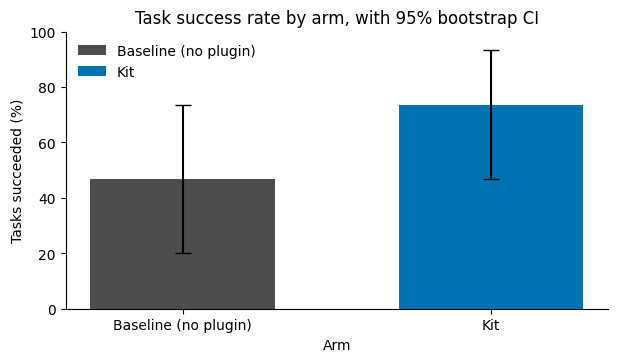

In [6]:
COLORS = ["#4D4D4D", "#0072B2", "#D55E00", "#009E73", "#CC79A7"]   # baseline first (dark grey), then colour-blind-safe
names = list(arms)
rate = np.array([arms[a]["success_rate"] for a in names]) * 100
lo = np.array([arms[a]["ci_low"] for a in names]) * 100
hi = np.array([arms[a]["ci_high"] for a in names]) * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, a in enumerate(names):
    ax.bar(i, rate[i], yerr=[[rate[i] - lo[i]], [hi[i] - rate[i]]], color=COLORS[i], capsize=6, width=0.6, label=a)
ax.set_xticks(range(len(names)), names)
ax.set_ylim(0, 100)
ax.set_title("Task success rate by arm, with 95% bootstrap CI")
ax.set_xlabel("Arm")
ax.set_ylabel("Tasks succeeded (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
save_figure(fig, "success_rate.pdf", "Task success rate by arm, with 95% bootstrap CI", "Arm", "Tasks succeeded (%)",
            names)


## Step 5. Numbers file for the report

**What:** writes `final_report/key_numbers.json`, a flat `{"MacroName": "value-as-printed-in-RESULT.md"}`
map (macro names letters only). `numbers_to_tex.py` turns it into LaTeX macros.
**Why:** the paper quotes only numbers that trace to saved outputs; `check_report.py` verifies each value
appears verbatim in RESULT.md or an `output/*.json`.
**Inputs:** `results`. **Outputs:** `final_report/key_numbers.json`.

In [7]:
base, kit = list(arms.values())[:2]   # TEMPLATE: arm 1 = baseline, arm 2 = the kit
key_numbers = {
    "NTrials": f"{results['n_trials']:,}",
    "BaselineSuccessPct": f"{base['success_rate'] * 100:.1f}",
    "KitSuccessPct": f"{kit['success_rate'] * 100:.1f}",
    "KitSuccessCILowPct": f"{kit['ci_low'] * 100:.1f}",
    "KitSuccessCIHighPct": f"{kit['ci_high'] * 100:.1f}",
    "BaselineCostPerTask": f"{base['cost_per_task']:.2f}",
    "KitCostPerTask": f"{kit['cost_per_task']:.2f}",
}
(FR / "key_numbers.json").write_text(json.dumps(key_numbers, indent=1), encoding="utf-8")
print(key_numbers)


{'NTrials': '30', 'BaselineSuccessPct': '46.7', 'KitSuccessPct': '73.3', 'KitSuccessCILowPct': '46.7', 'KitSuccessCIHighPct': '93.3', 'BaselineCostPerTask': '0.43', 'KitCostPerTask': '0.41'}


## Step 6. Verify the saved outputs (PASS / FAIL)

**What:** hashes every file in `output/` and compares it with the manifest checksums. For a finished
study the reference is `final_report/replication/MANIFEST.json` (`output_sha256`); while a study is still
being built, the first run records `output/CHECKSUMS.json` as the baseline and later runs compare with it.
**Why:** proves that Run All reproduced the saved results byte for byte (or tells you exactly which
files differ). A FAIL raises, so a headless run exits non-zero.
**Inputs:** `output/*`, the manifest. **Outputs:** the printed PASS / FAIL (and `CHECKSUMS.json` on the
first run).

In [8]:
######################### Verify #######################
manifest_path = FR / "replication" / "MANIFEST.json"
files = {"output/" + str(f.relative_to(OUT)).replace("\\", "/"): f for f in sorted(OUT.rglob("*"))
         if f.is_file() and "_cache" not in f.parts and f.name != "CHECKSUMS.json"}
current = {rel: sha256(f) for rel, f in files.items()}
if manifest_path.exists():
    reference, source = json.loads(manifest_path.read_text(encoding="utf-8"))["output_sha256"], "replication MANIFEST.json"
elif (OUT / "CHECKSUMS.json").exists():
    reference, source = json.loads((OUT / "CHECKSUMS.json").read_text(encoding="utf-8")), "output/CHECKSUMS.json"
else:
    (OUT / "CHECKSUMS.json").write_text(json.dumps(current, indent=1), encoding="utf-8")
    reference, source = current, "output/CHECKSUMS.json (baseline recorded on this first run)"
missing = [k for k in reference if k not in current]
differs = [k for k in reference if k in current and current[k] != reference[k]]
extra = [k for k in current if k not in reference]
print(f"reference: {source}")
print(f"outputs matching: {len(reference) - len(missing) - len(differs)}/{len(reference)}   missing {missing}   differs {differs}   not in reference {extra}")
VERIFY_OK = not missing and not differs
print(f"runtime {time.time() - T_START:.0f}s")
print("PASS" if VERIFY_OK else "FAIL")
assert VERIFY_OK, "saved outputs do not match the reference checksums (see lists above)"


reference: output/CHECKSUMS.json (baseline recorded on this first run)
outputs matching: 1/1   missing []   differs []   not in reference []
runtime 1s
PASS
